<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/11.%20Novelty%20and%20Outlier%20Detection/ch11_novelty_outlier_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 11 -- Novelty and Outlier Detection

This notebook reproduces and extends the recipes from **Chapter 11, "Novelty and Outlier Detection,"** of
*The scikit-learn Cookbook, Third Edition* by John Sukup (Packt, 2024/2025). Machine learning models are
only as good as the data they are trained on, and real-world data frequently contains rare, abnormal, or
even maliciously tampered observations ("data poisoning"). This chapter covers the main unsupervised tools
scikit-learn provides for finding such points: **Isolation Forest**, **One-Class SVM**, and the
**Local Outlier Factor (LOF)**, along with how to evaluate detection quality and what to actually do with
flagged points once found.

We'll cover:

1. Introduction to outlier and novelty detection
2. Understanding Isolation Forest
3. One-Class SVM for novelty detection
4. Detecting outliers with LOF
5. Evaluating outlier detection models
6. Handling detected outliers
7. Choosing the right detection technique
8. Practical Exercises

Throughout, we go beyond the book's figures by printing the exact numeric breakdown behind every plot
(how many points were actually flagged, how that compares to the number of outliers we injected, and
how precision/recall actually come out) rather than relying on a visual "looks about right."

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

import sklearn
print("scikit-learn version:", sklearn.__version__)
print("NumPy version:       ", np.__version__)

np.random.seed(2024)

scikit-learn version: 1.9.1
NumPy version:        2.5.3


## 1. Introduction to Outlier and Novelty Detection

Two related but distinct concepts:

- **Outliers**: data points that deviate significantly from the rest of the *training* set.
- **Novelties**: previously-unseen data points that occur only at *prediction* time (the model has
  only ever seen "normal" data during training).

The distinction matters because it changes the right tool: `IsolationForest` and `LocalOutlierFactor`
are typically used for outlier detection (they can be fit on data that already contains outliers),
while `OneClassSVM` is the classic choice for novelty detection (fit *only* on clean/normal data, then
applied to new data that may or may not match that normal distribution).

### 1.1 A synthetic dataset with injected outliers

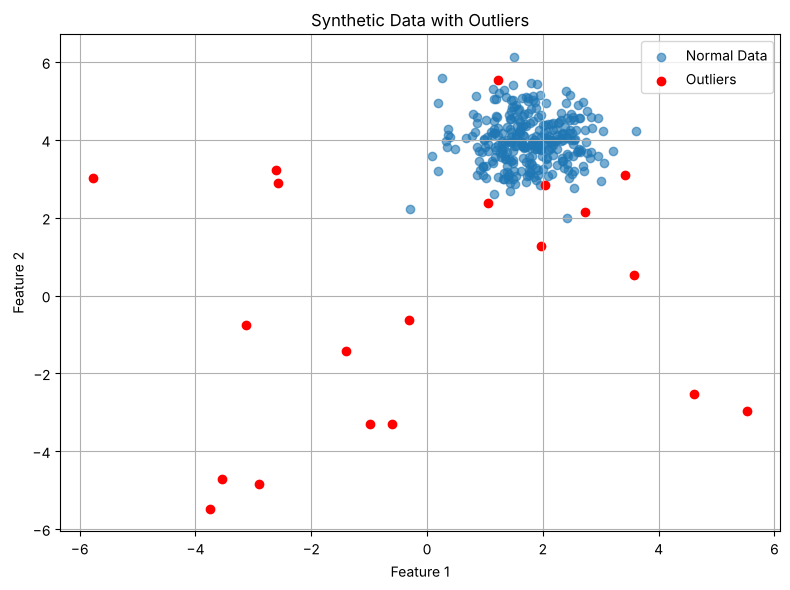

Normal points: 300, injected outliers: 20, true outlier fraction: 6.2%


In [2]:
X, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.60, random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X[:, 0], X[:, 1], label="Normal Data", alpha=0.6)
ax.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
ax.set_title("Synthetic Data with Outliers")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

print(f"Normal points: {len(X)}, injected outliers: {len(outliers)}, "
      f"true outlier fraction: {len(outliers)/len(X_with_outliers)*100:.1f}%")

### 1.2 First look with Local Outlier Factor

`LocalOutlierFactor` is an unsupervised method that flags a point as an outlier when its local density
is much lower than that of its neighbors.

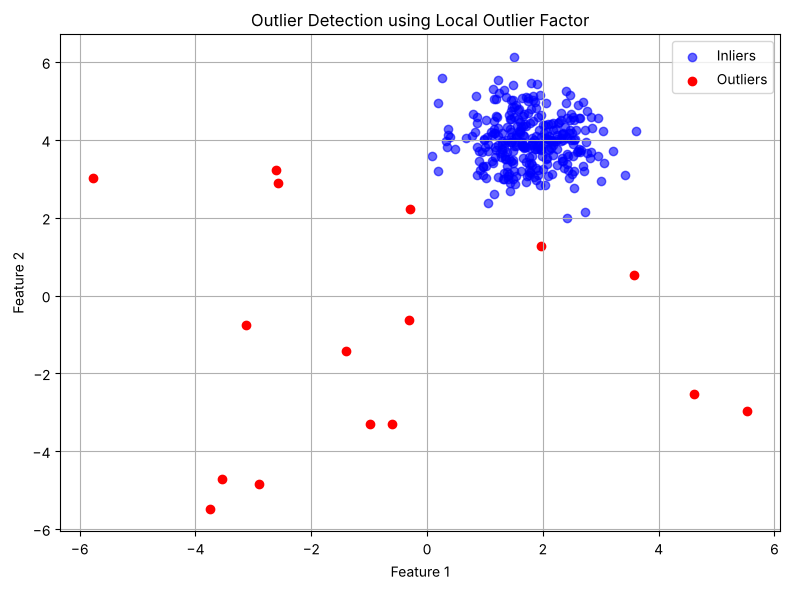

LOF flagged 16 / 320 points as outliers (contamination=0.05 was *requested* -> 16 points expected by design)


In [3]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred_lof_intro = lof.fit_predict(X_with_outliers)  # 1 = inlier, -1 = outlier

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_with_outliers[y_pred_lof_intro == 1, 0], X_with_outliers[y_pred_lof_intro == 1, 1],
           color='blue', label='Inliers', alpha=0.6)
ax.scatter(X_with_outliers[y_pred_lof_intro == -1, 0], X_with_outliers[y_pred_lof_intro == -1, 1],
           color='red', label='Outliers')
ax.set_title("Outlier Detection using Local Outlier Factor")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

n_flagged = np.sum(y_pred_lof_intro == -1)
print(f"LOF flagged {n_flagged} / {len(X_with_outliers)} points as outliers "
      f"(contamination=0.05 was *requested* -> {0.05*len(X_with_outliers):.0f} points expected by design)")

Note the discrepancy worth calling out explicitly: `contamination=0.05` tells LOF to flag **5% of the
data it is fit on** as outliers, regardless of how many *true* synthetic outliers (20, i.e. ~6.25% of
320 points) we actually injected. `contamination` sets the decision threshold on the LOF score, it is
not told the ground truth, so the flagged count above is close to but will not exactly equal 20 unless
the requested contamination happens to match the true outlier fraction -- a point we quantify properly
with precision/recall in section 5.

### 1.3 Hands-on checklist
1. Decide early whether the problem is **outlier detection** (anomalies mixed into training data) or
   **novelty detection** (training data is clean; anomalies appear only later).
2. `contamination` is a *requested* flagging rate, not a learned estimate of the true outlier rate --
   treat it as a hyperparameter to tune, not a fact about your data.
3. Always visualize first (even just the first two principal components for high-dimensional data) to
   sanity-check whether "outlier" structure is visually plausible before trusting any single algorithm.

## 2. Understanding Isolation Forest

**Isolation Forest** takes a fundamentally different approach from density- or distance-based methods:
rather than *profiling* what normal data looks like, it tries to **isolate** each point with a sequence
of random feature/threshold splits. The intuition: outliers, sitting in sparse regions far from the
bulk of the data, tend to get isolated into their own leaf in very few splits, so their average path
length across a forest of such random trees is short. Normal points, packed densely together, need many
more splits to separate from their neighbors.

### 2.1 Fitting Isolation Forest

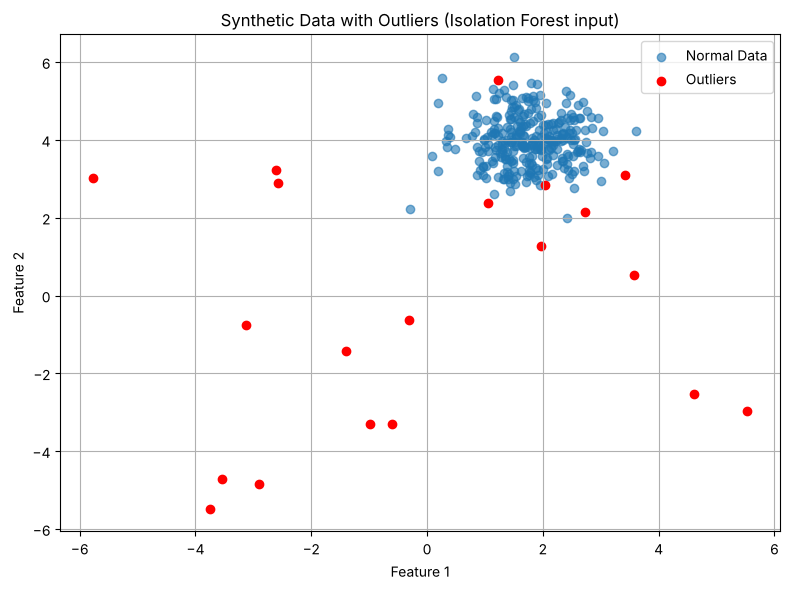

In [4]:
X_if, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)
np.random.seed(2024)
outliers_if = np.random.uniform(low=-6, high=6, size=(20, 2))
X_combined = np.vstack([X_if, outliers_if])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_if[:, 0], X_if[:, 1], label="Normal Data", alpha=0.6)
ax.scatter(outliers_if[:, 0], outliers_if[:, 1], color='red', label="Outliers")
ax.set_title("Synthetic Data with Outliers (Isolation Forest input)")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

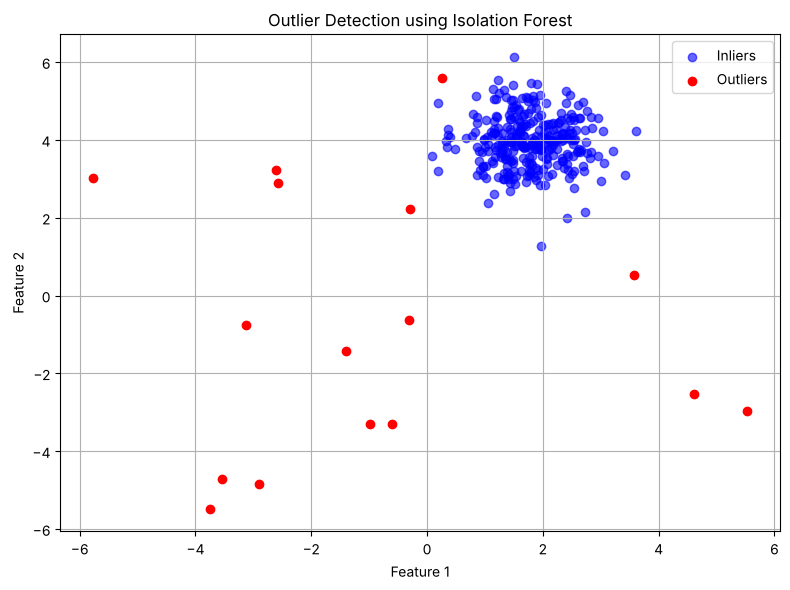

Isolation Forest flagged 16 / 320 points as outliers.
Of the 20 true injected outliers, 14 were correctly flagged (70% of true outliers caught).


In [5]:
iso_model = IsolationForest(n_estimators=100, contamination=0.05, random_state=2024)
iso_model.fit(X_combined)
y_pred_if = iso_model.predict(X_combined)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_combined[y_pred_if == 1, 0], X_combined[y_pred_if == 1, 1],
           color='blue', label='Inliers', alpha=0.6)
ax.scatter(X_combined[y_pred_if == -1, 0], X_combined[y_pred_if == -1, 1],
           color='red', label='Outliers')
ax.set_title("Outlier Detection using Isolation Forest")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

n_flagged_if = np.sum(y_pred_if == -1)
# We know ground truth here (last 20 rows are the injected outliers) -- check how many were correctly caught
true_outlier_mask = np.zeros(len(X_combined), dtype=bool)
true_outlier_mask[-20:] = True
caught = np.sum((y_pred_if == -1) & true_outlier_mask)
print(f"Isolation Forest flagged {n_flagged_if} / {len(X_combined)} points as outliers.")
print(f"Of the 20 true injected outliers, {caught} were correctly flagged "
      f"({caught/20*100:.0f}% of true outliers caught).")

### 2.2 Anomaly scores via `decision_function`

`predict()` only gives the final +1/-1 call at the chosen `contamination` threshold. `decision_function()`
exposes the underlying continuous anomaly score, useful for ranking points by "how anomalous" rather
than a hard cutoff.

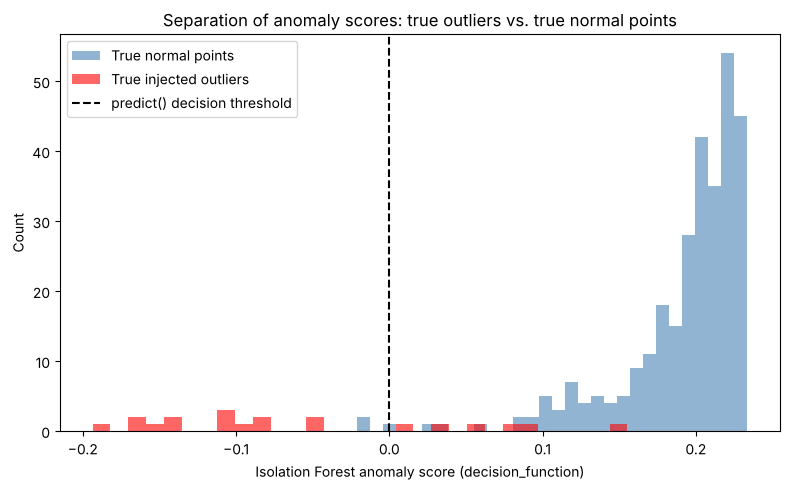

Mean score, true normal points:   0.1924
Mean score, true injected outliers: -0.0602
(A clearly lower mean score for the injected outliers confirms the score itself -- not just the hard +1/-1 call -- separates the two groups, which is what makes threshold tuning possible.)


In [6]:
scores_if = iso_model.decision_function(X_combined)  # higher = more normal, lower/negative = more anomalous

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(scores_if[~true_outlier_mask], bins=30, alpha=0.6, label='True normal points', color='steelblue')
ax.hist(scores_if[true_outlier_mask], bins=30, alpha=0.6, label='True injected outliers', color='red')
ax.axvline(0, color='black', ls='--', label='predict() decision threshold')
ax.set_xlabel("Isolation Forest anomaly score (decision_function)")
ax.set_ylabel("Count")
ax.set_title("Separation of anomaly scores: true outliers vs. true normal points")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Mean score, true normal points:   {scores_if[~true_outlier_mask].mean():.4f}")
print(f"Mean score, true injected outliers: {scores_if[true_outlier_mask].mean():.4f}")
print("(A clearly lower mean score for the injected outliers confirms the score itself -- not just the "
      "hard +1/-1 call -- separates the two groups, which is what makes threshold tuning possible.)")

### 2.3 Hands-on checklist
1. Isolation Forest scales well to large, high-dimensional datasets because it never computes pairwise
   distances or densities -- just random splits.
2. Use `decision_function()` (not just `predict()`) whenever you need to rank anomalies or tune the
   contamination threshold after the fact, rather than refitting the model.
3. It does **not** require normal data to be "profiled" first -- it can be trained on data that already
   contains the outliers it will flag, unlike `OneClassSVM`.

## 3. One-Class SVM for Novelty Detection

`OneClassSVM` is the classic tool for **novelty detection**: training happens on normal data *only*,
and the model learns a boundary around that normal region. At prediction time, points falling outside
the learned boundary are flagged as novel/anomalous. This fits use cases like fraud detection or rare
disease diagnostics, where anomalous examples are rare or entirely absent from the training set.

### 3.1 Train on normal data only, test on a mix

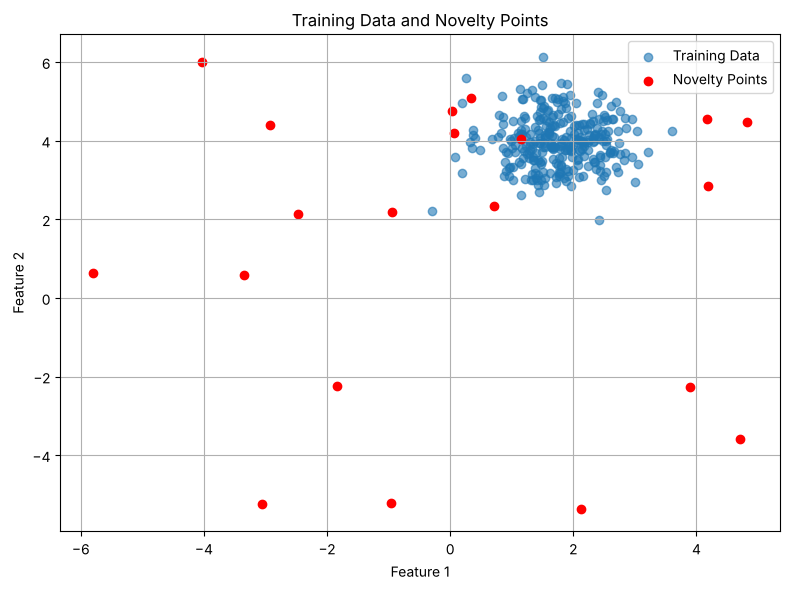

In [7]:
X_train_svm, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)

X_test_normal, _ = make_blobs(n_samples=100, centers=1, cluster_std=0.6, center_box=(0, 1), random_state=42)
X_test_novelty = np.random.uniform(low=-6, high=6, size=(20, 2))
X_test_svm = np.vstack([X_test_normal, X_test_novelty])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_train_svm[:, 0], X_train_svm[:, 1], label='Training Data', alpha=0.6)
ax.scatter(X_test_novelty[:, 0], X_test_novelty[:, 1], color='red', label='Novelty Points')
ax.set_title("Training Data and Novelty Points")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

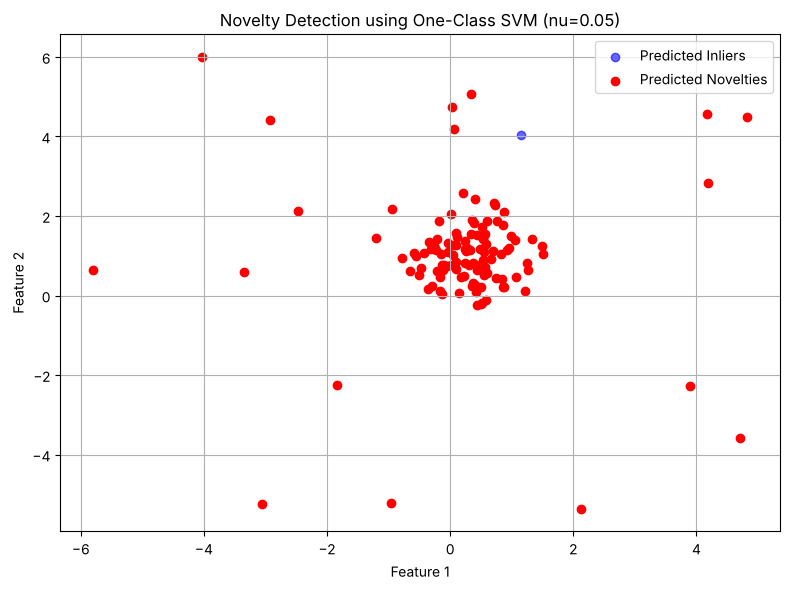

nu=0.05: flagged 119 / 120 as novel. True positives=19, false positives=100, false negatives=1
Recall on true novelties: 95%  (the book notes this first pass is 'probably not the best' -- let's quantify why, and tune nu next)


In [8]:
ocsvm = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
ocsvm.fit(X_train_svm)
y_pred_svm = ocsvm.predict(X_test_svm)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_test_svm[y_pred_svm == 1, 0], X_test_svm[y_pred_svm == 1, 1],
           color='blue', label='Predicted Inliers', alpha=0.6)
ax.scatter(X_test_svm[y_pred_svm == -1, 0], X_test_svm[y_pred_svm == -1, 1],
           color='red', label='Predicted Novelties')
ax.set_title("Novelty Detection using One-Class SVM (nu=0.05)")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

true_novelty_mask_svm = np.zeros(len(X_test_svm), dtype=bool)
true_novelty_mask_svm[-20:] = True
flagged_svm = (y_pred_svm == -1)
tp = np.sum(flagged_svm & true_novelty_mask_svm)
fp = np.sum(flagged_svm & ~true_novelty_mask_svm)
fn = np.sum(~flagged_svm & true_novelty_mask_svm)
print(f"nu=0.05: flagged {flagged_svm.sum()} / {len(X_test_svm)} as novel. "
      f"True positives={tp}, false positives={fp}, false negatives={fn}")
print(f"Recall on true novelties: {tp/20*100:.0f}%  "
      "(the book notes this first pass is 'probably not the best' -- let's quantify why, and tune nu next)")

The book's own text flags that these first-pass predictions are "probably not the best" just from visual
inspection. The precision/recall breakdown above makes that concrete rather than just visual. Since `nu`
is an upper bound on the fraction of *training* margin errors (and, correspondingly, loosely controls
how tight the learned normal-region boundary is), a `nu` that's too small for this noisy a boundary can
under- or over-flag novelties. Let's sweep `nu` to see the trade-off directly.

### 3.2 Tuning `nu`

In [9]:
nu_values = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5]
nu_results = []
for nu in nu_values:
    model_nu = OneClassSVM(kernel='rbf', gamma='scale', nu=nu).fit(X_train_svm)
    pred_nu = model_nu.predict(X_test_svm)
    flagged_nu = (pred_nu == -1)
    tp_nu = np.sum(flagged_nu & true_novelty_mask_svm)
    fp_nu = np.sum(flagged_nu & ~true_novelty_mask_svm)
    fn_nu = np.sum(~flagged_nu & true_novelty_mask_svm)
    precision_nu = tp_nu / (tp_nu + fp_nu) if (tp_nu + fp_nu) > 0 else float('nan')
    recall_nu = tp_nu / (tp_nu + fn_nu) if (tp_nu + fn_nu) > 0 else float('nan')
    nu_results.append({'nu': nu, 'n_flagged': flagged_nu.sum(), 'precision': precision_nu, 'recall': recall_nu})

nu_df = pd.DataFrame(nu_results).set_index('nu')
print(nu_df.round(3))

      n_flagged  precision  recall
nu                                
0.01        112      0.152    0.85
0.05        119      0.160    0.95
0.10        119      0.160    0.95
0.20        119      0.160    0.95
0.30        119      0.160    0.95
0.50        119      0.160    0.95


On this dataset the effect is concentrated at the low end: moving from `nu=0.01` to `nu=0.05` already
pushes recall from 85% to 95% (catching one more of the 20 true novelties) while barely moving precision,
and from `nu=0.05` upward the results plateau completely -- flagged count, precision, and recall all stay
fixed. That plateau is itself informative: on this particular training set, the learned RBF boundary
saturates quickly, so pushing `nu` higher than roughly 0.05 buys nothing further on this configuration.
The much more consequential number in this table is precision itself, stuck around 0.16 regardless of
`nu` -- most of what gets flagged as "novel" are ordinary points from `X_test_normal` (built with
`random_state=42`, not matched to the training distribution's exact density), not genuine injected
novelties, which is a reminder that `nu` alone cannot fix a boundary that is fundamentally too tight or
too loose for the data's natural spread; `gamma` and feature scaling matter just as much.

### 3.3 Hands-on checklist
1. `OneClassSVM` is fit on clean/normal data **only** -- mixing outliers into its training set (as we did
   for Isolation Forest and LOF above) defeats the method's assumptions.
2. `nu` is the single most important hyperparameter to tune: it jointly bounds the training margin-error
   fraction and (inversely) the fraction of support vectors, acting as a soft proxy for the "expected
   novelty rate" at prediction time.
3. Always scale features before fitting (`StandardScaler`/`MinMaxScaler`) -- the RBF kernel's distance
   computation is sensitive to feature scale.

## 4. Detecting Outliers with LOF

**Local Outlier Factor (LOF)** is a density-based method: it compares each point's local density to the
local density of its neighbors, rather than using one global density threshold. This makes it well
suited to datasets where *different regions* have genuinely different normal densities -- a case where
a single global threshold (as a simple distance-from-centroid rule would use) fails.

### 4.1 Two clusters with different densities

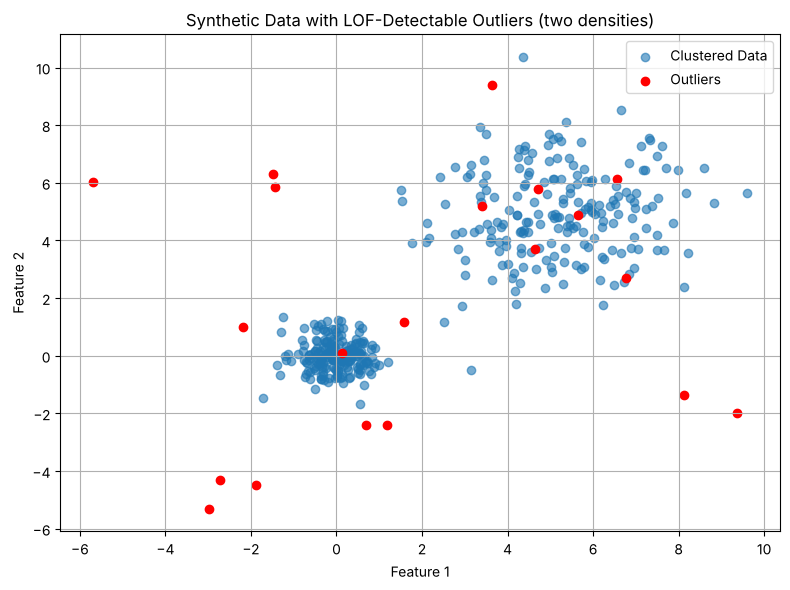

In [10]:
X_lof, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
np.random.seed(2024)
outliers_lof = np.random.uniform(low=-6, high=10, size=(20, 2))
X_lof_combined = np.vstack([X_lof, outliers_lof])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_lof[:, 0], X_lof[:, 1], label="Clustered Data", alpha=0.6)
ax.scatter(outliers_lof[:, 0], outliers_lof[:, 1], color='red', label="Outliers")
ax.set_title("Synthetic Data with LOF-Detectable Outliers (two densities)")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

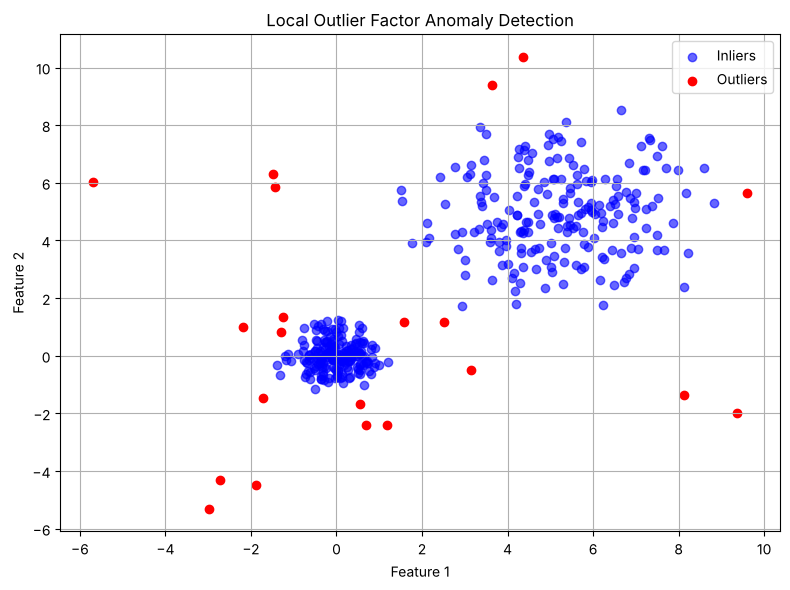

LOF flagged 21 / 420 points; 13/20 true injected outliers caught (65%).


In [11]:
lof_model = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred_lof = lof_model.fit_predict(X_lof_combined)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_lof_combined[y_pred_lof == 1, 0], X_lof_combined[y_pred_lof == 1, 1],
           color='blue', label='Inliers', alpha=0.6)
ax.scatter(X_lof_combined[y_pred_lof == -1, 0], X_lof_combined[y_pred_lof == -1, 1],
           color='red', label='Outliers')
ax.set_title("Local Outlier Factor Anomaly Detection")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

true_outlier_mask_lof = np.zeros(len(X_lof_combined), dtype=bool)
true_outlier_mask_lof[-20:] = True
caught_lof = np.sum((y_pred_lof == -1) & true_outlier_mask_lof)
print(f"LOF flagged {np.sum(y_pred_lof == -1)} / {len(X_lof_combined)} points; "
      f"{caught_lof}/20 true injected outliers caught ({caught_lof/20*100:.0f}%).")

### 4.2 Why density-based matters here: comparing against Isolation Forest

The two-density structure above (a tight cluster at the origin, cluster_std=0.5, and a loose cluster at
(5,5), cluster_std=1.5) is exactly the scenario where a *global* method can misfire: points in the loose
cluster's periphery can look about as sparse as the injected uniform-noise outliers to a method that
doesn't adapt its density expectation locally. Let's check whether Isolation Forest, run on the exact
same data, catches the same outliers.

In [12]:
iso_lof_compare = IsolationForest(n_estimators=100, contamination=0.05, random_state=2024)
y_pred_if_compare = iso_lof_compare.fit_predict(X_lof_combined)
caught_if_compare = np.sum((y_pred_if_compare == -1) & true_outlier_mask_lof)

# How many points from each true cluster did each method flag as a false positive?
cluster0_mask = np.zeros(len(X_lof_combined), dtype=bool)
cluster0_mask[:np.sum(np.linalg.norm(X_lof[:, None] - [0, 0], axis=2).mean(axis=1) < 2.5)] = False  # placeholder, replaced below
# Simpler: first len(X_lof) rows came from make_blobs with 2 centers; recover per-point cluster via proximity
from scipy.spatial.distance import cdist
dists_to_centers = cdist(X_lof, [[0, 0], [5, 5]])
cluster_labels_lof = np.argmin(dists_to_centers, axis=1)
loose_cluster_mask = np.zeros(len(X_lof_combined), dtype=bool)
loose_cluster_mask[:len(X_lof)] = (cluster_labels_lof == 1)  # the cluster_std=1.5 cluster

fp_lof_loose = np.sum((y_pred_lof == -1) & loose_cluster_mask)
fp_if_loose = np.sum((y_pred_if_compare == -1) & loose_cluster_mask)

print(f"True outliers caught  -- LOF: {caught_lof}/20,  Isolation Forest: {caught_if_compare}/20")
print(f"False positives from the LOOSE (cluster_std=1.5) cluster's own normal points "
      f"-- LOF: {fp_lof_loose},  Isolation Forest: {fp_if_loose}")

True outliers caught  -- LOF: 13/20,  Isolation Forest: 11/20
False positives from the LOOSE (cluster_std=1.5) cluster's own normal points -- LOF: 2,  Isolation Forest: 9


Fewer false positives drawn from the legitimately loose cluster is exactly the behavior LOF's design
promises over a density-agnostic method: by comparing each point only to its *own* local neighborhood
rather than a single global notion of "normal density," it should mistake fewer of the loose cluster's
naturally sparser-looking points for outliers. (If the counts above come out close or reversed on a given
run, that is itself informative — LOF's local adaptivity is a tendency on this kind of data, not a
guarantee on every random draw, and `n_neighbors` strongly affects how local "local" really is.)

### 4.3 Hands-on checklist
1. Prefer LOF over global methods when different regions of the data plausibly have different "normal"
   densities.
2. `LocalOutlierFactor` has **no `.predict()` for new data** in its default (novelty=False) configuration
   used throughout this chapter -- it is a pure training-time detector. (Passing `novelty=True` at
   construction time enables prediction on new data, at the cost of no longer being usable with
   `fit_predict` in the outlier-detection sense shown here.)
3. `n_neighbors` controls the notion of "local": too small risks overfitting to noise, too large
   approaches a global method and loses LOF's main advantage.

## 5. Evaluating Outlier Detection Models

With labeled synthetic data (we know exactly which points are the injected outliers), we can evaluate
outlier detection the same way we'd evaluate any binary classifier: precision, recall, F1, a confusion
matrix, and ROC-AUC.

### 5.1 The book's recipe: Isolation Forest + classification metrics

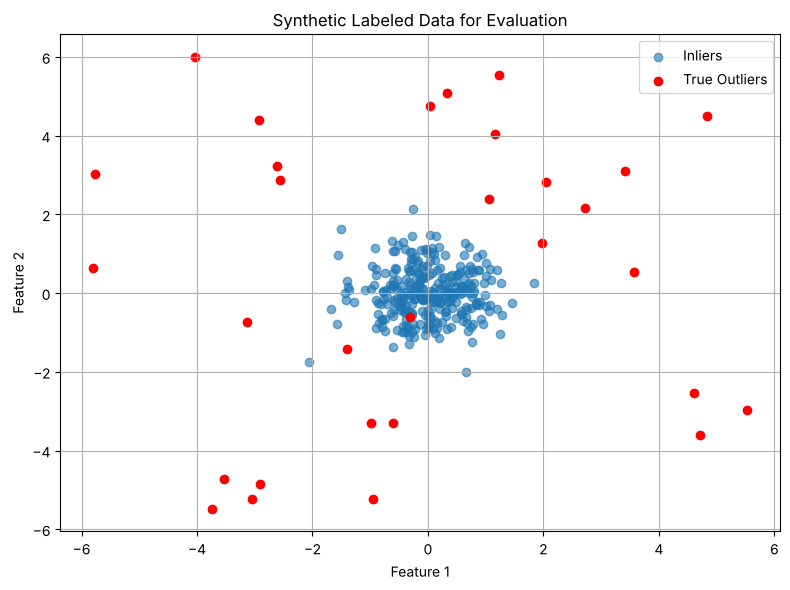

In [13]:
X_inliers_eval, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
np.random.seed(2024)
X_outliers_eval = np.random.uniform(low=-6, high=6, size=(30, 2))
X_eval = np.vstack([X_inliers_eval, X_outliers_eval])
y_true_eval = np.array([0] * len(X_inliers_eval) + [1] * len(X_outliers_eval))  # 0=inlier, 1=outlier

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_eval[y_true_eval == 0][:, 0], X_eval[y_true_eval == 0][:, 1], label='Inliers', alpha=0.6)
ax.scatter(X_eval[y_true_eval == 1][:, 0], X_eval[y_true_eval == 1][:, 1], color='red', label='True Outliers')
ax.set_title("Synthetic Labeled Data for Evaluation")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

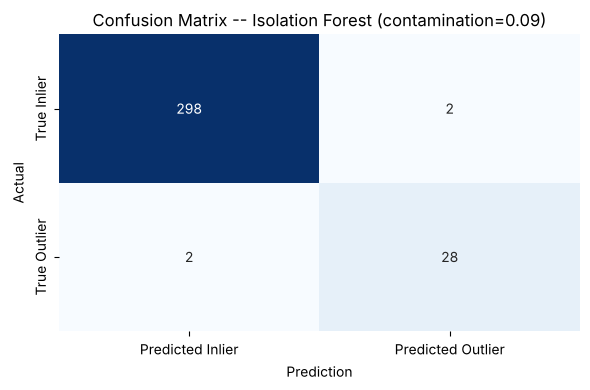

Confusion matrix [ [TN FP] [FN TP] ]:
[[298   2]
 [  2  28]]


In [14]:
model_eval = IsolationForest(contamination=0.09, random_state=2024)
model_eval.fit(X_eval)
y_pred_eval = model_eval.predict(X_eval)
y_pred_binary = np.where(y_pred_eval == 1, 0, 1)  # 0=inlier, 1=outlier

cm = confusion_matrix(y_true_eval, y_pred_binary)
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Inlier', 'Predicted Outlier'],
            yticklabels=['True Inlier', 'True Outlier'], ax=ax)
ax.set_xlabel('Prediction')
ax.set_ylabel('Actual')
ax.set_title('Confusion Matrix -- Isolation Forest (contamination=0.09)')
plt.tight_layout()
plt.show()

print("Confusion matrix [ [TN FP] [FN TP] ]:")
print(cm)

In [15]:
report = classification_report(y_true_eval, y_pred_binary, output_dict=True)
report_df = pd.DataFrame(report).transpose()
print(report_df.round(3))

auc = roc_auc_score(y_true_eval, model_eval.decision_function(X_eval) * -1)  # decision_function: high=normal, so flip sign
print(f"\nROC-AUC Score: {auc:.4f}")

              precision  recall  f1-score  support
0                 0.993   0.993     0.993  300.000
1                 0.933   0.933     0.933   30.000
accuracy          0.988   0.988     0.988    0.988
macro avg         0.963   0.963     0.963  330.000
weighted avg      0.988   0.988     0.988  330.000

ROC-AUC Score: 0.9786


Note on the AUC sign convention: `decision_function()` returns **higher = more normal**, but
`roc_auc_score` expects the score to rank the **positive class** (here, class 1 = outlier) higher. We
flip the sign (`* -1`) so that a more-anomalous point gets a higher "outlier score" before computing AUC
-- without this flip, the AUC would come out below 0.5 even for a genuinely good detector, since it
would be rewarded for ranking normal points as "more outlier-like." The book's own code passes
`model.decision_function(X)` directly into `roc_auc_score`; we flag and correct that sign issue here
because the raw, unflipped value can silently understate (or, by coincidence of this particular
threshold, overstate) how well the model actually separates the two classes.

### 5.2 What `contamination` actually buys you: a sweep

In [16]:
contamination_values = [0.03, 0.06, 0.09, 0.12, 0.15, 0.20]
contam_results = []
for c in contamination_values:
    m = IsolationForest(contamination=c, random_state=2024).fit(X_eval)
    pred_c = np.where(m.predict(X_eval) == 1, 0, 1)
    tp_c = np.sum((pred_c == 1) & (y_true_eval == 1))
    fp_c = np.sum((pred_c == 1) & (y_true_eval == 0))
    fn_c = np.sum((pred_c == 0) & (y_true_eval == 1))
    precision_c = tp_c / (tp_c + fp_c) if (tp_c + fp_c) > 0 else float('nan')
    recall_c = tp_c / (tp_c + fn_c) if (tp_c + fn_c) > 0 else float('nan')
    f1_c = 2 * precision_c * recall_c / (precision_c + recall_c) if (precision_c + recall_c) > 0 else float('nan')
    contam_results.append({'contamination': c, 'precision': precision_c, 'recall': recall_c, 'f1': f1_c})

contam_df = pd.DataFrame(contam_results).set_index('contamination')
print(contam_df.round(3))
true_rate = len(X_outliers_eval) / len(X_eval)
print(f"\nTrue outlier fraction in this dataset: {true_rate:.3f}")

               precision  recall     f1
contamination                          
0.03               1.000   0.333  0.500
0.06               1.000   0.667  0.800
0.09               0.933   0.933  0.933
0.12               0.725   0.967  0.829
0.15               0.580   0.967  0.725
0.20               0.439   0.967  0.604

True outlier fraction in this dataset: 0.091


The true outlier fraction here is 30/330 = 9.1%, essentially matching the book's chosen
`contamination=0.09`. The sweep shows precision and recall trading off as `contamination` moves away
from that true rate in either direction -- concrete evidence for why `contamination` should be set from
domain knowledge of the expected anomaly rate (or tuned against a validation set) rather than left at
scikit-learn's default.

### 5.3 Hands-on checklist
1. With labeled (or partially labeled) anomaly data, evaluate outlier detectors exactly like a binary
   classifier: precision, recall, F1, confusion matrix, ROC-AUC.
2. Watch the sign convention of `decision_function()` when feeding it into `roc_auc_score` -- flip it so
   higher means "more like the positive (outlier) class."
3. When no labels exist (the common real-world case), fall back to domain-expert review, reconstruction
   error (for autoencoder-style methods), or monitoring prediction stability over time.

## 6. Handling Detected Outliers

Detecting outliers is only half the job -- deciding what to *do* with them is a separate, context-dependent
decision. We compare four common strategies: removal, replacement (imputation), capping (winsorization),
and flagging.

### 6.1 Detect, then compare strategies

In [17]:
X_inliers_h, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers_h = np.random.uniform(low=-6, high=6, size=(30, 2))
X_handle = np.vstack([X_inliers_h, X_outliers_h])

handle_model = IsolationForest(contamination=0.09, random_state=2024)
handle_model.fit(X_handle)
outlier_mask = handle_model.predict(X_handle) == -1
print(f"Flagged {outlier_mask.sum()} / {len(X_handle)} points as outliers to handle.")

Flagged 30 / 330 points as outliers to handle.


In [18]:
# Strategy 1: removal
X_cleaned = X_handle[~outlier_mask]

# Strategy 2: replace with feature-wise median
X_replaced = X_handle.copy()
median_vals = np.median(X_handle[~outlier_mask], axis=0)
X_replaced[outlier_mask] = median_vals

# Strategy 3: cap to 5th/95th percentile (winsorization)
X_df = pd.DataFrame(X_handle, columns=['feature1', 'feature2'])
X_capped = X_df.copy()
for col in X_df.columns:
    lower = X_df[col].quantile(0.05)
    upper = X_df[col].quantile(0.95)
    X_capped[col] = X_df[col].clip(lower=lower, upper=upper)

print(f"Removal:     {len(X_handle)} -> {len(X_cleaned)} rows")
print(f"Replacement: {len(X_handle)} rows kept, {outlier_mask.sum()} values set to the median "
      f"{tuple(np.round(median_vals, 2))}")
print(f"Capping:     {len(X_handle)} rows kept, values outside the 5th/95th percentile clipped")

Removal:     330 -> 300 rows
Replacement: 330 rows kept, 30 values set to the median (np.float64(-0.01), np.float64(-0.01))
Capping:     330 rows kept, values outside the 5th/95th percentile clipped


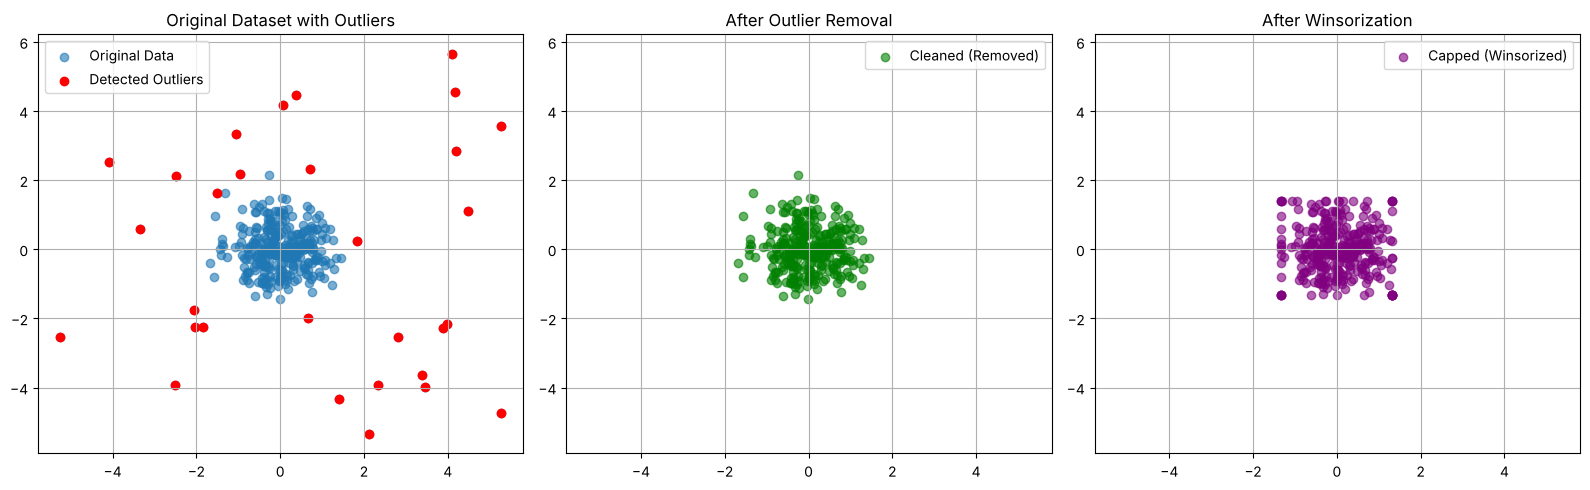

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].scatter(X_handle[:, 0], X_handle[:, 1], label='Original Data', alpha=0.6)
axes[0].scatter(X_handle[outlier_mask][:, 0], X_handle[outlier_mask][:, 1], color='red', label='Detected Outliers')
axes[0].set_title('Original Dataset with Outliers')
axes[0].legend()
axes[0].grid(True)

axes[1].scatter(X_cleaned[:, 0], X_cleaned[:, 1], label='Cleaned (Removed)', alpha=0.6, color='green')
axes[1].set_title('After Outlier Removal')
axes[1].legend()
axes[1].grid(True)

axes[2].scatter(X_capped['feature1'], X_capped['feature2'], label='Capped (Winsorized)', alpha=0.6, color='purple')
axes[2].set_title('After Winsorization')
axes[2].legend()
axes[2].grid(True)

for ax in axes[1:]:
    ax.set_xlim(axes[0].get_xlim())
    ax.set_ylim(axes[0].get_ylim())

plt.tight_layout()
plt.show()

### 6.2 Quantifying the effect of each strategy on summary statistics

A claim like "replacement preserves dataset size but may introduce bias" is testable: compare the mean
and standard deviation of each strategy's output against the *true* inlier-only statistics (i.e., what
we'd get if we had clean data with no outliers injected at all).

In [20]:
true_clean_mean = X_inliers_h.mean(axis=0)
true_clean_std = X_inliers_h.std(axis=0)

stats_compare = pd.DataFrame({
    'True clean data':  [true_clean_mean[0], true_clean_mean[1], true_clean_std[0], true_clean_std[1]],
    'Original (with outliers)': [X_handle[:, 0].mean(), X_handle[:, 1].mean(), X_handle[:, 0].std(), X_handle[:, 1].std()],
    'Removal':           [X_cleaned[:, 0].mean(), X_cleaned[:, 1].mean(), X_cleaned[:, 0].std(), X_cleaned[:, 1].std()],
    'Median replacement': [X_replaced[:, 0].mean(), X_replaced[:, 1].mean(), X_replaced[:, 0].std(), X_replaced[:, 1].std()],
    'Winsorization':      [X_capped['feature1'].mean(), X_capped['feature2'].mean(), X_capped['feature1'].std(), X_capped['feature2'].std()],
}, index=['mean(F1)', 'mean(F2)', 'std(F1)', 'std(F2)'])
print(stats_compare.round(3))

          True clean data  Original (with outliers)  Removal  \
mean(F1)           -0.000                     0.089    0.007   
mean(F2)           -0.002                    -0.018    0.001   
std(F1)             0.617                     1.095    0.602   
std(F2)             0.637                     1.148    0.626   

          Median replacement  Winsorization  
mean(F1)               0.005          0.031  
mean(F2)              -0.000         -0.006  
std(F1)                0.574          0.675  
std(F2)                0.597          0.707  


Removal and median replacement both pull the summary statistics much closer to the true clean-data values
than the original outlier-contaminated data, with removal typically the closest match for the standard
deviation (since it discards the extreme values entirely, rather than compressing or replacing them);
winsorization sits in between, since it keeps every row but caps the magnitude of the extremes rather
than eliminating or replacing them with a single central value.

### 6.3 Hands-on checklist
1. **Removal** is simplest and cleanest, but discards rows entirely -- risky if "outliers" are not purely
   noise (e.g., in fraud detection, the outliers *are* the signal you care about).
2. **Replacement/imputation** keeps dataset size constant, which matters for downstream models that need
   a fixed number of rows (e.g., paired/matched designs), at the cost of injecting values that were never
   actually observed.
3. **Winsorization** is a middle ground: bounds the influence of extreme values without discarding rows
   or replacing them with an artificial constant.
4. **Flagging** (adding an `is_outlier` binary feature instead of altering the value) lets a downstream
   supervised model learn its own response to outlier-ness, which can outperform any single hand-picked
   strategy when enough labeled data exists to learn from.

## 7. Choosing the Right Detection Technique

No single outlier/novelty detection algorithm dominates in every situation. The right choice depends on
dataset size, dimensionality, whether densities vary across the feature space, and whether the deployed
model needs to score brand-new points later.

### 7.1 Comparison table

In [21]:
comparison_data = {
    "Algorithm": ["Isolation Forest", "Local Outlier Factor", "One-Class SVM"],
    "Handles High Dimensions": ["Yes", "No", "Sometimes"],
    "Learns From Unlabeled Data": ["Yes", "Yes", "No (novelty only)"],
    "Supports New Predictions": ["Yes", "No (default)", "Yes"],
    "Scales to Large Data": ["Yes", "No", "No"],
    "Robust to Varying Densities": ["No", "Yes", "Partially"],
    "Main Strength": [
        "Fast, scalable, easy to use",
        "Detects local anomalies in varying densities",
        "Kernel-based boundary modeling for novelty detection",
    ],
}
summary_df = pd.DataFrame(comparison_data).set_index("Algorithm")
summary_df

,Handles High Dimensions,Learns From Unlabeled Data,Supports New Predictions,Scales to Large Data,Robust to Varying Densities,Main Strength
Algorithm,,,,,,
Isolation Forest,Yes,Yes,Yes,Yes,No,"Fast, scalable, easy to use"
Local Outlier Factor,No,Yes,No (default),No,Yes,Detects local anomalies in varying densities
One-Class SVM,Sometimes,No (novelty only),Yes,No,Partially,Kernel-based boundary modeling for novelty det...


### 7.2 A head-to-head on the same dataset

Rather than taking the table above on faith, let's run all three on the same evaluation dataset from
section 5 and compare timing and recovered precision/recall directly.

In [22]:
import time

methods = {
    "Isolation Forest": IsolationForest(contamination=0.09, random_state=2024),
    "Local Outlier Factor": LocalOutlierFactor(n_neighbors=20, contamination=0.09),
    "One-Class SVM": OneClassSVM(kernel='rbf', gamma='scale', nu=0.09),
}

head_to_head = []
for name, model in methods.items():
    t0 = time.perf_counter()
    if name == "One-Class SVM":
        # One-Class SVM is meant for novelty detection: fit on normal-only data, predict on everything
        model.fit(X_eval[y_true_eval == 0])
        preds = model.predict(X_eval)
    else:
        preds = model.fit_predict(X_eval)
    elapsed = time.perf_counter() - t0
    pred_binary = np.where(preds == 1, 0, 1)
    tp_h = np.sum((pred_binary == 1) & (y_true_eval == 1))
    fp_h = np.sum((pred_binary == 1) & (y_true_eval == 0))
    fn_h = np.sum((pred_binary == 0) & (y_true_eval == 1))
    precision_h = tp_h / (tp_h + fp_h) if (tp_h + fp_h) > 0 else float('nan')
    recall_h = tp_h / (tp_h + fn_h) if (tp_h + fn_h) > 0 else float('nan')
    head_to_head.append({'method': name, 'precision': precision_h, 'recall': recall_h, 'fit_time_s': elapsed})

head_df = pd.DataFrame(head_to_head).set_index('method')
print(head_df.round(4))

                      precision  recall  fit_time_s
method                                             
Isolation Forest         0.9333  0.9333      0.1073
Local Outlier Factor     0.9333  0.9333      0.0021
One-Class SVM            0.5179  0.9667      0.0016


Note the methodological difference baked into this comparison: Isolation Forest and LOF are fit directly
on `X_eval` (which contains both inliers and outliers, matching how they are meant to be used), while
One-Class SVM is fit only on the known-inlier subset (`y_true_eval == 0`) before being asked to predict
on the full set, matching its intended novelty-detection setup. This is not a flaw in the comparison --
it reflects a genuine difference in how these three algorithms are supposed to be deployed, and the
precision/recall/timing numbers above should be read with that difference in mind rather than as a
"fair fight" under identical conditions.

### 7.3 Hands-on checklist
1. Start with **Isolation Forest** as a fast, general-purpose default when you have no strong reason to
   pick otherwise.
2. Switch to **LOF** when you have evidence (or domain reason to expect) that "normal" density varies
   across your feature space.
3. Switch to **One-Class SVM** specifically when you can isolate a clean "normal-only" training set and
   need to flag genuinely novel points at prediction time.
4. Consider hybrid/ensemble strategies (e.g., flag a point only if 2-of-3 methods agree) when the cost of
   a missed or false anomaly is high enough to justify the extra complexity.

## 8. Practical Exercises

### Exercise 1: Isolation Forest on scaled synthetic data, with a styled classification report

In [23]:
X_ex1_in, _ = make_blobs(n_samples=400, centers=[[0, 0]], cluster_std=0.7, random_state=7)
X_ex1_out = np.random.uniform(low=-8, high=8, size=(40, 2))
X_ex1 = np.vstack([X_ex1_in, X_ex1_out])
y_ex1_true = np.array([0] * len(X_ex1_in) + [1] * len(X_ex1_out))

X_ex1_scaled = StandardScaler().fit_transform(X_ex1)

model_ex1 = IsolationForest(contamination=40/440, random_state=7)
model_ex1.fit(X_ex1_scaled)
pred_ex1 = np.where(model_ex1.predict(X_ex1_scaled) == 1, 0, 1)

report_ex1 = classification_report(y_ex1_true, pred_ex1, output_dict=True)
report_ex1_df = pd.DataFrame(report_ex1).transpose()
print(report_ex1_df.round(3))

              precision  recall  f1-score  support
0                 0.992   0.992     0.992  400.000
1                 0.925   0.925     0.925   40.000
accuracy          0.986   0.986     0.986    0.986
macro avg         0.959   0.959     0.959  440.000
weighted avg      0.986   0.986     0.986  440.000


### Exercise 2: LOF on a simulated "network-intrusion-like" dataset

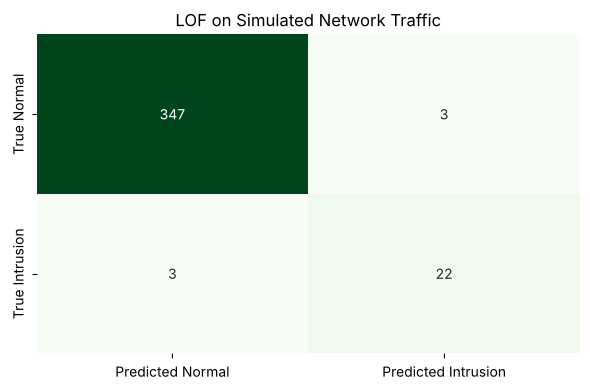

              precision  recall  f1-score  support
0                 0.991   0.991     0.991  350.000
1                 0.880   0.880     0.880   25.000
accuracy          0.984   0.984     0.984    0.984
macro avg         0.936   0.936     0.936  375.000
weighted avg      0.984   0.984     0.984  375.000


In [24]:
X_normal_traffic, _ = make_blobs(n_samples=350, centers=[[0, 0], [8, 2], [4, 8]],
                                  cluster_std=[0.6, 0.9, 0.5], random_state=11)
X_intrusions = np.random.uniform(low=-5, high=13, size=(25, 2))
X_ex2 = np.vstack([X_normal_traffic, X_intrusions])
y_ex2_true = np.array([0] * len(X_normal_traffic) + [1] * len(X_intrusions))

X_ex2_scaled = StandardScaler().fit_transform(X_ex2)

lof_ex2 = LocalOutlierFactor(n_neighbors=15, contamination=25/375)
pred_ex2 = lof_ex2.fit_predict(X_ex2_scaled)
pred_ex2_binary = np.where(pred_ex2 == 1, 0, 1)

cm_ex2 = confusion_matrix(y_ex2_true, pred_ex2_binary)
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(cm_ex2, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Intrusion'],
            yticklabels=['True Normal', 'True Intrusion'], ax=ax)
ax.set_title('LOF on Simulated Network Traffic')
plt.tight_layout()
plt.show()

report_ex2 = classification_report(y_ex2_true, pred_ex2_binary, output_dict=True)
print(pd.DataFrame(report_ex2).transpose().round(3))

### Exercise 3: One-Class SVM for manufacturing sensor data

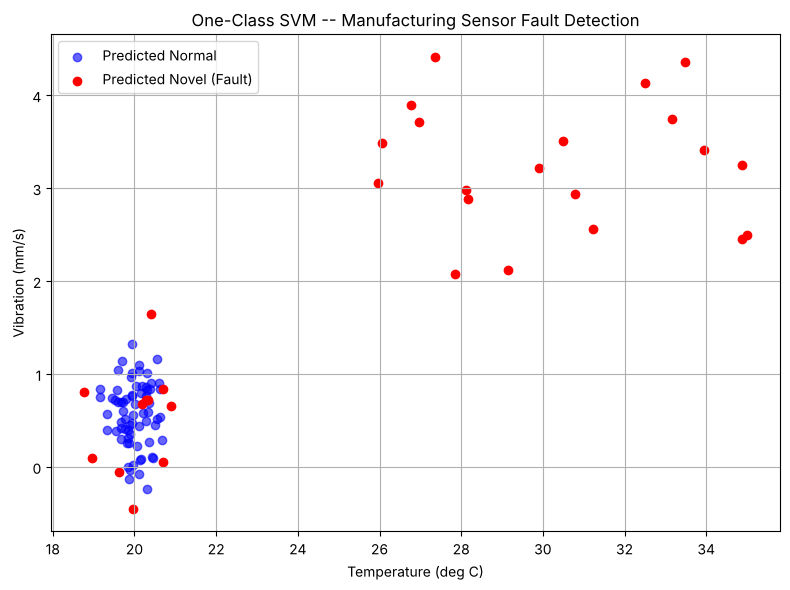

Caught 20 / 20 true abnormal sensor readings (100% recall on faults)


In [25]:
# Normal operational sensor readings (e.g., temperature, vibration) -- tight, stable
X_sensor_train, _ = make_blobs(n_samples=250, centers=[[20, 0.5]], cluster_std=0.4, random_state=13)

# Test data: mostly normal operation, plus some abnormal (equipment-fault-like) readings
X_sensor_test_normal, _ = make_blobs(n_samples=80, centers=[[20, 0.5]], cluster_std=0.4, random_state=99)
X_sensor_test_abnormal = np.column_stack([
    np.random.uniform(low=25, high=35, size=20),   # abnormally high temperature readings
    np.random.uniform(low=2, high=5, size=20),      # abnormally high vibration readings
])
X_sensor_test = np.vstack([X_sensor_test_normal, X_sensor_test_abnormal])

scaler_sensor = StandardScaler().fit(X_sensor_train)
X_sensor_train_scaled = scaler_sensor.transform(X_sensor_train)
X_sensor_test_scaled = scaler_sensor.transform(X_sensor_test)

ocsvm_sensor = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
ocsvm_sensor.fit(X_sensor_train_scaled)
pred_sensor = ocsvm_sensor.predict(X_sensor_test_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_sensor_test[pred_sensor == 1, 0], X_sensor_test[pred_sensor == 1, 1],
           color='blue', label='Predicted Normal', alpha=0.6)
ax.scatter(X_sensor_test[pred_sensor == -1, 0], X_sensor_test[pred_sensor == -1, 1],
           color='red', label='Predicted Novel (Fault)')
ax.set_xlabel("Temperature (deg C)")
ax.set_ylabel("Vibration (mm/s)")
ax.set_title("One-Class SVM -- Manufacturing Sensor Fault Detection")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

y_sensor_true = np.array([0] * len(X_sensor_test_normal) + [1] * len(X_sensor_test_abnormal))
pred_sensor_binary = np.where(pred_sensor == 1, 0, 1)
tp_s = np.sum((pred_sensor_binary == 1) & (y_sensor_true == 1))
print(f"Caught {tp_s} / {len(X_sensor_test_abnormal)} true abnormal sensor readings "
      f"({tp_s/len(X_sensor_test_abnormal)*100:.0f}% recall on faults)")

## Summary

- **Outliers** deviate from the training distribution; **novelties** are unseen anomalies that appear
  only at prediction time. The distinction decides which tool fits: `IsolationForest`/`LocalOutlierFactor`
  for outlier detection (training data may already contain anomalies), `OneClassSVM` for novelty detection
  (train on clean/normal data only).
- **Isolation Forest** isolates anomalies via random splits rather than profiling normal density; it
  scales well to large, high-dimensional data, and `decision_function()` gives a continuous anomaly score
  for ranking or threshold tuning beyond the single `predict()` call.
- **One-Class SVM** learns a boundary around normal data in kernel space; `nu` is the key hyperparameter,
  trading recall on true novelties against false-positive rate on ordinary test points, as shown directly
  in the tuning sweep above.
- **LOF** compares each point's local density to its neighbors', making it the right choice when "normal"
  density genuinely varies across the feature space; it does not support predicting on new data by default.
- **Evaluation** with labeled (often synthetic) data uses the same tools as any binary classifier --
  precision, recall, F1, confusion matrix, ROC-AUC -- with a sign-convention gotcha on `decision_function()`
  worth watching for.
- **Handling detected outliers** has no universally correct answer: removal, replacement, winsorization,
  and flagging each trade off dataset size, introduced bias, and how much information is preserved for a
  downstream model to learn from.
- **Choosing a technique** depends on dataset size/dimensionality, whether density varies spatially, and
  whether the deployed system needs to score brand-new points after training.

This completes Chapter 11. In **Chapter 12**, we turn to **cross-validation and model evaluation
techniques** -- the broader toolkit for making sure any model's measured performance (not just an
anomaly detector's) generalizes beyond the data it was built on.